<a href="https://colab.research.google.com/github/alketola/satellite-stuff/blob/main/AkeSatelliteOrbit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

We will build this educational project in 8 stages:
1. **Setup**: Imports, constants, file paths, and configuration (Current Stage)
2. **Load GP JSON**: Load General Perturbations data of satellites
3. **Parse Elements**: Convert SGP4 mean elements into Keplerian parameters
4. **Time Window**: Define simulation start, stop, and time steps
5. **Propagate**: Compute positions using a simple two-body Keplerian model
6. **Orbit Summary**: Extract ground track, altitude, period, and visibility window
7. **Plots**: Visualize the orbit in 3D, and ground tracks on a 2D map
8. **KML and Report**: Export satellite tracks to KML and compile a report

In [2]:
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import requests

# --- Constants ---
# Standard gravitational parameter for Earth (km^3/s^2)
MU_EARTH_KM3_S2 = 398600.4418
# Earth's equatorial radius (km)
EARTH_RADIUS_KM = 6378.137

# --- Directory Setup ---
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'input'
OUT_DIR = BASE_DIR / 'output'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Simulation Configuration ---
STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = None  # Optional parameter for potential later extensions

# --- Print Configuration to Verify ---
print("=== Stage 1: Setup Complete ===")
print(f"Gravity Parameter (MU): {MU_EARTH_KM3_S2} km^3/s^2")
print(f"Earth Radius: {EARTH_RADIUS_KM} km")
print(f"Input Directory: {IN_DIR}")
print(f"Output Directory: {OUT_DIR}")
print(f"Time Step: {STEP_SECONDS} s, Duration: {DURATION_HOURS} h, Live Group: {LIVE_GROUP}")

=== Stage 1: Setup Complete ===
Gravity Parameter (MU): 398600.4418 km^3/s^2
Earth Radius: 6378.137 km
Input Directory: /content/satellite_orbits/input
Output Directory: /content/satellite_orbits/output
Time Step: 5 s, Duration: 24 h, Live Group: None


### Why OMM JSON is Superior to TLE
The Orbit Mean-Elements Message (OMM) JSON format provides structured, human-readable keys for orbital parameters instead of the compact, rigid, and cryptic columns of traditional Two-Line Element (TLE) cards. Furthermore, it avoids parsing errors by representing dates in standard ISO-8601 strings and handles five-to-six-digit catalog numbers without complex column overflow hacks.

In [3]:
def extract_inputs():
    """
    Checks if the required files are present in IN_DIR.
    If not, polls /content/ for a zip file containing them and extracts it.
    """
    required_files = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_exist = all((IN_DIR / f).is_file() for f in required_files)

    if all_exist:
        print("Required input files already present in input directory.")
        return

    # Instruct user to upload the zip
    print("=================== ACTION REQUIRED ===================")
    print("Please drag 'orbit_workshop_inputs.zip' into the Colab Files panel (under /content).")
    print("Polling /content/ for the zip file...")
    print("========================================================")

    content_dir = Path('/content')
    zip_path = None
    timeout_seconds = 900  # 15 minutes
    start_time = time.time()

    while True:
        # Look for any zip file that matches the pattern
        zip_files = list(content_dir.glob('orbit_workshop_inputs*.zip'))
        for f in zip_files:
            if zipfile.is_zipfile(f):
                zip_path = f
                break
        if zip_path:
            break

        if time.time() - start_time > timeout_seconds:
            raise TimeoutError("Timed out waiting for 'orbit_workshop_inputs.zip' upload (15 min limit).")

        time.sleep(2)

    print(f"Found completed zip: {zip_path.name}. Extracting required files...")
    with zipfile.ZipFile(zip_path, 'r') as zf:
        for name in required_files:
            # Extract only the specified files directly to IN_DIR
            try:
                # Handle potential subfolders inside the zip if they exist
                matching_paths = [m for m in zf.namelist() if m.endswith(name)]
                if not matching_paths:
                    raise FileNotFoundError(f"Could not find '{name}' inside the zip archive.")

                # Write the file directly to IN_DIR
                with zf.open(matching_paths[0]) as source, open(IN_DIR / name, 'wb') as target:
                    target.write(source.read())
            except Exception as e:
                raise RuntimeError(f"Error extracting '{name}': {e}")

    print("Extraction complete!")


def read_gp_json(path):
    """
    Loads OMM JSON file and verifies that required GP keys exist for all entries.
    """
    required_keys = {
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    }

    if not path.is_file():
        raise FileNotFoundError(f"Cannot read GP elements; {path} does not exist.")

    with open(path, 'r') as f:
        try:
            data = json.load(f)
        except json.JSONDecodeError as e:
            raise ValueError(f"Invalid JSON syntax in {path}: {e}")

    if not isinstance(data, list):
        # Single object encapsulation if not wrapped in a list
        data = [data]

    for i, record in enumerate(data):
        missing = required_keys - record.keys()
        if missing:
            raise ValueError(f"Record at index {i} ({record.get('OBJECT_NAME', 'UNKNOWN')}) is missing keys: {missing}")

    return data

# --- Execution of Stage 2 ---
extract_inputs()

# Load datasets
sats = read_gp_json(IN_DIR / 'orbital_elements.json')
with open(IN_DIR / 'data_manifest.json', 'r') as f:
    data_manifest = json.load(f)

source_note = f"Data source: {data_manifest.get('source', 'Unknown')} (retrieved UTC: {data_manifest.get('retrieved_utc', 'N/A')})"
print("\n=== Satellites Loaded successfully ===")
print(source_note)
print(f"Total Satellites loaded: {len(sats)}")
print("-" * 50)
for s in sats:
    print(f"Name: {s['OBJECT_NAME']:<18} | NORAD ID: {s['NORAD_CAT_ID']:<6} | Epoch: {s['EPOCH']}")


=================== ACTION REQUIRED ===================
Please drag 'orbit_workshop_inputs.zip' into the Colab Files panel (under /content).
Polling /content/ for the zip file...
Found completed zip: orbit_workshop_inputs.zip. Extracting required files...
Extraction complete!

=== Satellites Loaded successfully ===
Data source: Unknown (retrieved UTC: 2026-11-10T16:30:32Z)
Total Satellites loaded: 4
--------------------------------------------------
Name: PULSAR-0           | NORAD ID: 64541  | Epoch: 2026-11-10T04:10:34.900320
Name: GSAT0225 (GALILEO 29) | NORAD ID: 59598  | Epoch: 2026-11-09T08:30:06.579648
Name: SES-5              | NORAD ID: 38652  | Epoch: 2026-11-10T04:02:09.139776
Name: QZS-2 (MICHIBIKI-2) | NORAD ID: 42738  | Epoch: 2026-10-17T15:21:52.982784


### Stage 3: Converting Mean Elements to Keplerian Elements

To compute satellite positions using a two-body approximation, we must convert the mean elements in Orbit Mean-Elements Messages (OMM) to Keplerian elements in standard physical units ($km$, $rad$, $rad/s$).

| GP Field Name | Keplerian Element | Symbol | Conversion in Code |
| :--- | :--- | :---: | :--- |
| `MEAN_MOTION` | Mean Motion | $n$ | Converts from $\text{rev/day}$ to $\text{rad/s}$ using $\frac{2\pi}{86400}$ |
| - | Semi-major axis | $a$ | Solved via Kepler's 3rd Law: $a = \left(\frac{\mu}{n^2}\right)^{1/3}$ |
| `ECCENTRICITY` | Eccentricity | $e$ | None (already a decimal ratio) |
| `INCLINATION` | Inclination | $i$ | Converts from degrees to radians |
| `RA_OF_ASC_NODE`| Right Ascension of Ascending Node | $\Omega$ | Converts from degrees to radians |
| `ARG_OF_PERICENTER`| Argument of Perigee | $\omega$ | Converts from degrees to radians |
| `MEAN_ANOMALY` | Mean Anomaly at Epoch | $M_0$ | Converts from degrees to radians |

> **Note:** The General Perturbations (GP) values in CelesTrak are "SGP4 mean elements" derived by filtering out short-period gravitational and atmospheric perturbations. Using them in a pure two-body Keplerian propagator is an educational approximation, not a precision orbit prediction.

In [4]:
def parse_gp_epoch(text):
    """
    Parses ISO-8601 UTC epoch strings into timezone-aware datetimes.
    CelesTrak sometimes omits the explicit 'Z' suffix, but epochs are always UTC.
    """
    clean_text = text.rstrip('Z')
    return datetime.fromisoformat(clean_text).replace(tzinfo=timezone.utc)


def parse_gp_elements(rec):
    """
    Converts a single GP dictionary record (OMM fields) into Keplerian model parameters.
    """
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Mean motion: rev/day -> rad/s
    mean_motion_rev_day = rec['MEAN_MOTION']
    n_rad_s = (2.0 * math.pi * mean_motion_rev_day) / 86400.0

    # Semi-major axis (a) from Kepler's third law: a^3 = mu / n^2
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)

    # Angular elements: degrees -> radians
    i_rad = math.radians(rec['INCLINATION'])
    raan_rad = math.radians(rec['RA_OF_ASC_NODE'])
    argp_rad = math.radians(rec['ARG_OF_PERICENTER'])
    M0_rad = math.radians(rec['MEAN_ANOMALY'])

    return {
        'name': name,
        'norad_id': norad_id,
        'label': f"{name} [{norad_id}]",
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': rec['ECCENTRICITY'],
        'i_rad': i_rad,
        'raan_rad': raan_rad,
        'argp_rad': argp_rad,
        'M0_rad': M0_rad
    }


def elements_table(elements_list):
    """
    Constructs a formatted text table displaying satellite Keplerian parameters.
    """
    lines = []
    header = f"{'Satellite Name':<18} | {'NORAD':<5} | {'Epoch (UTC)':<23} | {'a (km)':<9} | {'e':<8} | {'i (deg)':<7} | {'RAAN':<6} | {'ARGP':<6} | {'M0':<6}"
    divider = "-" * len(header)
    lines.append(header)
    lines.append(divider)

    for el in elements_list:
        line = (f"{el['name']:<18} | "
                f"{el['norad_id']:<5} | "
                f"{el['epoch'].strftime('%Y-%m-%d %H:%M:%S'):<23} | "
                f"{el['a_km']:>9.2f} | "
                f"{el['e']:>8.6f} | "
                f"{math.degrees(el['i_rad']):>7.2f} | "
                f"{math.degrees(el['raan_rad']):>6.1f} | "
                f"{math.degrees(el['argp_rad']):>6.1f} | "
                f"{math.degrees(el['M0_rad']):>6.1f}")
        lines.append(line)
    return lines


# --- Execution of Stage 3 ---
# Ensure sats variable exists from previous stage
if 'sats' not in globals():
    raise ValueError("Stage 2 output not found! Please run preceding cells first.")

elements = [parse_gp_elements(s) for s in sats]
for line in elements_table(elements):
    print(line)

Satellite Name     | NORAD | Epoch (UTC)             | a (km)    | e        | i (deg) | RAAN   | ARGP   | M0    
----------------------------------------------------------------------------------------------------------------
PULSAR-0           | 64541 | 2026-11-10 04:10:34     |   6880.97 | 0.000408 |   97.48 |   67.6 |   54.2 |  306.0
GSAT0225 (GALILEO 29) | 59598 | 2026-11-09 08:30:06     |  29600.26 | 0.000159 |   55.22 |   97.0 |  171.2 |  226.9
SES-5              | 38652 | 2026-11-10 04:02:09     |  42164.28 | 0.000191 |    0.05 |   32.2 |  188.0 |  254.7
QZS-2 (MICHIBIKI-2) | 42738 | 2026-10-17 15:21:52     |  42170.36 | 0.074521 |   39.25 |  241.4 |  270.9 |  243.8


### Stage 4: Defining a Common Simulation Time Grid

Because every satellite's orbit is initialized at a slightly different time (its individual `epoch`), we must define a single, common UTC time grid to simulate their trajectories simultaneously.

This offset is highly critical: our simple two-body Keplerian propagator does not model non-spherical Earth perturbations, solar radiation pressure, or atmospheric drag. Because we propagate forward starting from each satellite's own epoch, the prediction error grows with the elapsed time offset. As we will see, some records like QZS-2 are several weeks older than the newest epoch, meaning their simulated positions will suffer from significant error accumulation.

In [5]:
# --- Stage 4: Time Window Generation and Epoch Checking ---
if 'elements' not in globals():
    raise ValueError("Stage 3 elements list not found! Please run the previous cells first.")

# 1. Determine simulation start (newest epoch in elements, floored to UTC midnight)
newest_epoch = max(el['epoch'] for el in elements)
sim_start = newest_epoch.replace(hour=0, minute=0, second=0, microsecond=0)
sim_end = sim_start + timedelta(hours=DURATION_HOURS)

# 2. Build the common UTC time grid
time_span_seconds = int((sim_end - sim_start).total_seconds())
n_points = (time_span_seconds // STEP_SECONDS) + 1
times = [sim_start + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

print("=== Simulation Time Window ===")
print(f"Start (UTC): {sim_start}")
print(f"End   (UTC): {sim_end}")
print(f"Step (s)   : {STEP_SECONDS}")
print(f"Grid Points: {n_points:,}")
print("-" * 50)

# 3. Calculate and verify epoch offsets for each satellite
print(f"{'Satellite Name':<22} | {'Epoch (UTC)':<23} | {'Offset (days)':<13} | {'Status'}")
print("-" * 70)
for el in elements:
    # Offset calculated as: sim_start - satellite_epoch
    offset_days = (sim_start - el['epoch']).total_seconds() / 86400.0
    is_stale = offset_days > 7.0
    status = "⚠️ STALE RECORD" if is_stale else "OK"
    print(f"{el['name']:<22} | {el['epoch'].strftime('%Y-%m-%d %H:%M:%S'):<23} | {offset_days:>13.2f} | {status}")

=== Simulation Time Window ===
Start (UTC): 2026-11-10 00:00:00+00:00
End   (UTC): 2026-11-11 00:00:00+00:00
Step (s)   : 5
Grid Points: 17,281
--------------------------------------------------
Satellite Name         | Epoch (UTC)             | Offset (days) | Status
----------------------------------------------------------------------
PULSAR-0               | 2026-11-10 04:10:34     |         -0.17 | OK
GSAT0225 (GALILEO 29)  | 2026-11-09 08:30:06     |          0.65 | OK
SES-5                  | 2026-11-10 04:02:09     |         -0.17 | OK
QZS-2 (MICHIBIKI-2)    | 2026-10-17 15:21:52     |         23.36 | ⚠️ STALE RECORD


### Stage 5: Orbital Propagation Physics

In this stage, we implement the core physical propagation logic based on a **two-body Keplerian model**, an **analytical Kepler solver**, and **IAU-1982 Greenwich Mean Sidereal Time (GMST)** rotation to convert inertial trajectories into Earth-fixed coordinates.

#### Physics Breakdown:
1. **Mean Anomaly ($M$)**: Extrapolated linearly in time: $M = M_0 + n \cdot (t - t_{\text{epoch}})$.
2. **Kepler's Equation Solver ($E$)**: Uses the Newton-Raphson iterative method to solve the transcendental equation $M = E - e \sin E$ for Eccentric Anomaly ($E$).
3. **Orbital Coordinates**: Determines distance from center ($r$) and True Anomaly ($\nu$). Combined with Argument of Perigee ($\omega$), this gives the Argument of Latitude ($u = \omega + \nu$).
4. **Inertial Coordinates ($x, y, z$)**: Converts orbit-plane coordinates to Geocentric Equatorial Inertial (GEI) coordinates by rotating through Inclination ($i$) and Right Ascension of Ascending Node ($\Omega$).
5. **Earth-Fixed Coordinates ($x', y', z'$)**: Rotates the GEI coordinates around the Z-axis by the Greenwich Mean Sidereal Time (GMST, $\theta_G$) to align with the rotating Earth (ECEF frame).
6. **Geodetic Coordinates (Lat, Lon, Alt)**: Assuming a spherical Earth, maps Earth-fixed coordinates to Latitude, Longitude, and Altitude above the mean radius.
7. **Vis-Viva Speed ($v$)**: Computes instant orbital speed using the vis-viva equation $v = \sqrt{\mu \left(\frac{2}{r} - \frac{1}{a}\right)}$.

In [6]:
# --- Stage 5: Propagation Mechanics ---
if 'elements' not in globals() or 'times' not in globals():
    raise ValueError("Stage 3/4 outputs not found! Please run previous cells first.")

def solve_kepler(M, e):
    """
    Solves Kepler's equation M = E - e * sin(E) using Newton-Raphson.
    """
    # 1. Starting estimate
    E = math.pi if e > 0.8 else M
    tol = 1e-12
    for _ in range(50):
        f = E - e * math.sin(E) - M
        f_prime = 1.0 - e * math.cos(E)
        delta = f / f_prime
        E -= delta
        if abs(delta) < tol:
            return E
    raise RuntimeError(f"Kepler solver failed to converge for M={M}, e={e}")

def gmst_rad(t):
    """
    Computes Greenwich Mean Sidereal Time (GMST) in radians using IAU-1982 formula.
    """
    # J2000 epoch is 2000-01-01 12:00:00 UTC
    j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    d = (t - j2000).total_seconds() / 86400.0
    T = d / 36525.0

    # GMST in degrees
    theta_deg = (280.46061837 + 360.98564736629 * d + 0.000387933 * (T ** 2) - (T ** 3) / 38710000.0)
    return math.radians(theta_deg % 360.0)

def propagate(el, times_list):
    """
    Propagates a satellite's orbit over a list of UTC times.
    """
    track = []
    epoch = el['epoch']
    n = el['n_rad_s']
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']

    for t in times_list:
        # Step 1: Mean Anomaly
        dt_sec = (t - epoch).total_seconds()
        M = (M0 + n * dt_sec) % (2.0 * math.pi)

        # Step 2: Eccentric Anomaly
        E = solve_kepler(M, e)

        # Step 3: Orbit Plane Coordinates (Distance and Argument of Latitude)
        r = a * (1.0 - e * math.cos(E))
        nu = math.atan2(math.sqrt(1.0 - e**2) * math.sin(E), math.cos(E) - e)
        u = argp + nu

        # Step 4: Geocentric Equatorial Inertial position (x, y, z)
        cos_u, sin_u = math.cos(u), math.sin(u)
        cos_raan, sin_raan = math.cos(raan), math.sin(raan)
        cos_i, sin_i = math.cos(i), math.sin(i)

        x = r * (cos_raan * cos_u - sin_raan * sin_u * cos_i)
        y = r * (sin_raan * cos_u + cos_raan * sin_u * cos_i)
        z = r * sin_u * sin_i

        # Step 5: Rotate into Earth-fixed axes (ECEF) by Greenwich Mean Sidereal Time
        theta = gmst_rad(t)
        cos_theta, sin_theta = math.cos(theta), math.sin(theta)
        x_prime = cos_theta * x + sin_theta * y
        y_prime = -sin_theta * x + cos_theta * y

        # Step 6: Spherical latitude, longitude (degrees) and altitude
        lat_deg = math.degrees(math.atan2(z, math.hypot(x_prime, y_prime)))
        lon_deg = math.degrees(math.atan2(y_prime, x_prime))
        alt_km = r - EARTH_RADIUS_KM

        # Step 7: Vis-Viva speed (km/s)
        speed_km_s = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / a))

        track.append({
            'time': t,
            'lat_deg': lat_deg,
            'lon_deg': lon_deg,
            'alt_km': alt_km,
            'speed_km_s': speed_km_s
        })

    return track

# --- Verification Assertions ---
# 1. Verify GMST at J2000 is approx 280.46 deg
j2000_epoch = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
gmst_j2000_deg = math.degrees(gmst_rad(j2000_epoch))
assert abs(gmst_j2000_deg - 280.46061837) < 1e-5, f"GMST test failed: {gmst_j2000_deg}"

# 2. Kepler Residual verification
test_E = solve_kepler(1.5, 0.1)
residual = abs(test_E - 0.1 * math.sin(test_E) - 1.5)
assert residual < 1e-10, f"Kepler solver tolerance check failed: residual = {residual}"

# 3. Propagate and inspect
tracks = [propagate(el, times) for el in elements]

# 4. Check SES-5 Geostationary longitude (should stay around 5 degrees East)
ses5_index = next((idx for idx, el in enumerate(elements) if el['norad_id'] == 38652), None)
if ses5_index is not None:
    ses5_lons = [pt['lon_deg'] for pt in tracks[ses5_index]]
    min_lon, max_lon = min(ses5_lons), max(ses5_lons)
    print(f"SES-5 (GEO 5.0E) tracked longitude range: {min_lon:.2f} to {max_lon:.2f} East")
    assert all(4.0 <= lon <= 6.0 for lon in ses5_lons), \
        f"SES-5 drifted outside 4.0 - 6.0 E range! Range: {min_lon:.2f} to {max_lon:.2f}"

print("\n=== Verification Checks Passed successfully ===\n")

# --- Output Propagated Tracks for Each Satellite ---
for i, el in enumerate(elements):
    track = tracks[i]
    print(f"Satellite: {el['label']}")
    print("-" * 80)
    for name, idx in [("First", 0), ("Middle", len(track) // 2), ("Last", -1)]:
        pt = track[idx]
        print(f"  {name:<6} Point | {pt['time'].strftime('%H:%M:%S')} | Lat: {pt['lat_deg']:>6.2f} | Lon: {pt['lon_deg']:>7.2f} | Alt: {pt['alt_km']:>8.1f} km | Speed: {pt['speed_km_s']:>5.2f} km/s")
    print()

SES-5 (GEO 5.0E) tracked longitude range: 4.99 to 5.03 East

=== Verification Checks Passed successfully ===

Satellite: PULSAR-0 [64541]
--------------------------------------------------------------------------------
  First  Point | 00:00:00 | Lat:  51.99 | Lon: -151.86 | Alt:    502.0 km | Speed:  7.61 km/s
  Middle Point | 12:00:00 | Lat: -14.79 | Lon: -160.05 | Alt:    501.8 km | Speed:  7.61 km/s
  Last   Point | 00:00:00 | Lat: -22.73 | Lon: -165.68 | Alt:    505.2 km | Speed:  7.61 km/s

Satellite: GSAT0225 (GALILEO 29) [59598]
--------------------------------------------------------------------------------
  First  Point | 00:00:00 | Lat:  52.28 | Lon:  111.76 | Alt:  23222.7 km | Speed:  3.67 km/s
  Middle Point | 12:00:00 | Lat:  17.32 | Lon: -120.13 | Alt:  23226.2 km | Speed:  3.67 km/s
  Last   Point | 00:00:00 | Lat: -25.70 | Lon:   27.34 | Alt:  23226.4 km | Speed:  3.67 km/s

Satellite: SES-5 [38652]
--------------------------------------------------------------------

In [7]:
# --- Verification Check: GMST at J2000 ---
j2000_epoch = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
gmst_j2000_rad = gmst_rad(j2000_epoch)
gmst_j2000_deg = math.degrees(gmst_j2000_rad)

print("GMST at J2000 Epoch (UTC: 2000-01-01 12:00:00):")
print(f"- Radians: {gmst_j2000_rad:.8f} rad")
print(f"- Degrees: {gmst_j2000_deg:.6f}")

# Verification test
target_value = 280.46061837
tolerance = 1e-5
is_equal = abs(gmst_j2000_deg - target_value) < tolerance

if is_equal:
    print(f"\nSuccess! GMST at J2000 matches the target value of {target_value} within a tolerance of {tolerance}.")
else:
    print(f"\nMismatch: GMST is {gmst_j2000_deg}, expected {target_value}.")

GMST at J2000 Epoch (UTC: 2000-01-01 12:00:00):
- Radians: 4.89496121 rad
- Degrees: 280.460618

Success! GMST at J2000 matches the target value of 280.46061837 within a tolerance of 1e-05.


### Stage 6: Orbit Summary Interpretations

By summarizing the simulated trajectories, we can identify and classify each satellite's operational profile based on physical Keplerian characteristics:

* **PULSAR-0**: Orbiting close to Earth with a period of about **1.58 hours** (95 minutes) and an inclination ($i$) near **97.5°**. This is a retrograde, near-polar, **Sun-Synchronous Orbit (SSO)** typical of Earth observation missions.
* **GSAT0225 (Galileo 29)**: Possesses a period of approximately **14.08 hours** at an inclination of **55.2°**. This matches the medium Earth orbit (MEO) profile optimized for global navigation satellite constellations.
* **SES-5**: Orbiting with a period of **23.93 hours** (one sidereal day) at a near-flat inclination ($i \approx 0.05^\circ$). This is a classic equatorial **Geostationary (GEO)** orbit that remains fixed over the same point on Earth.
* **QZS-2 (Michibiki-2)**: Also has a period of **23.93 hours** (one sidereal day), but features a higher eccentricity ($e \approx 0.07$) and a distinct inclination ($i \approx 39^\circ$). This designates it as an **Inclined Geosynchronous Orbit (IGSO)**, sweeping out a figure-eight ground track over East Asia and Oceania.

In [8]:
# --- Stage 6: Orbit Summarization and Analysis ---
if 'elements' not in globals() or 'tracks' not in globals():
    raise ValueError("Stage 3/5 outputs not found! Please run the preceding cells first.")

def orbit_summary(el, pts):
    """
    Extracts Keplerian invariants and calculates actual speed ranges from propagated tracks.
    """
    name = el['name']
    norad_id = el['norad_id']
    a = el['a_km']
    e = el['e']

    # Period in hours: T = 2 * pi / n (where n is rad/s)
    period_h = (2.0 * math.pi / el['n_rad_s']) / 3600.0

    # Perigee/Apogee altitudes above a spherical Earth
    perigee_km = a * (1.0 - e) - EARTH_RADIUS_KM
    apogee_km = a * (1.0 + e) - EARTH_RADIUS_KM

    # Speeds from the simulated track points
    speeds = [pt['speed_km_s'] for pt in pts]
    min_speed = min(speeds)
    max_speed = max(speeds)

    return {
        'name': name,
        'norad_id': norad_id,
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': e,
        'i_deg': math.degrees(el['i_rad']),
        'min_speed_km_s': min_speed,
        'max_speed_km_s': max_speed
    }

def summary_table(summaries_list):
    """
    Generates lines for a text table summarizing the physical attributes of each satellite.
    """
    lines = []
    header = f"{'Satellite Name':<18} | {'NORAD':<5} | {'Period (h)':<10} | {'Perigee (km)':<12} | {'Apogee (km)':<11} | {'e':<8} | {'i (deg)':<7} | {'Vmin (km/s)':<11} | {'Vmax (km/s)'}"
    divider = "-" * len(header)
    lines.append(header)
    lines.append(divider)

    for s in summaries_list:
        line = (f"{s['name']:<18} | "
                f"{s['norad_id']:<5} | "
                f"{s['period_h']:>10.2f} | "
                f"{s['perigee_km']:>12.1f} | "
                f"{s['apogee_km']:>11.1f} | "
                f"{s['e']:>8.6f} | "
                f"{s['i_deg']:>7.2f} | "
                f"{s['min_speed_km_s']:>11.3f} | "
                f"{s['max_speed_km_s']:>11.3f}")
        lines.append(line)
    return lines

# --- Process and Compile summaries ---
summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

# --- Assert Galileo 29 physical limits if present ---
galileo_sum = next((s for s in summaries if s['norad_id'] == 59598), None)
if galileo_sum is not None:
    print(f"Verifying Galileo 29 (NORAD 59598) Period: {galileo_sum['period_h']:.4f} hours")
    assert 14.0 <= galileo_sum['period_h'] <= 14.2, \
        f"Galileo 29 period of {galileo_sum['period_h']:.4f} hours is outside the [14.0, 14.2] hours bracket!"

# --- Print Summary Table ---
print("\n=== Satellite Orbit Summaries ===")
for line in summary_table(summaries):
    print(line)

Verifying Galileo 29 (NORAD 59598) Period: 14.0783 hours

=== Satellite Orbit Summaries ===
Satellite Name     | NORAD | Period (h) | Perigee (km) | Apogee (km) | e        | i (deg) | Vmin (km/s) | Vmax (km/s)
---------------------------------------------------------------------------------------------------------------------
PULSAR-0           | 64541 |       1.58 |        500.0 |       505.6 | 0.000408 |   97.48 |       7.608 |       7.614
GSAT0225 (GALILEO 29) | 59598 |      14.08 |      23217.4 |     23226.8 | 0.000159 |   55.22 |       3.669 |       3.670
SES-5              | 38652 |      23.93 |      35778.1 |     35794.2 | 0.000191 |    0.05 |       3.074 |       3.075
QZS-2 (MICHIBIKI-2) | 42738 |      23.94 |      32649.6 |     38934.8 | 0.074521 |   39.25 |       2.853 |       3.313


```markdown
### Stage 7: Ground Tracks and Velocity Analysis

In this stage, we visualize the simulated 24-hour trajectories in two complementary ways: a **2D Ground Track Map** and a **Velocity Time-Series Plot**.

#### Ground Track Interpretations:
* **PULSAR-0**: Shows dense, repeating orbital stripes shifting westward across the world map. This occurs because the satellite is in a Low Earth Orbit (LEO) with a very short orbital period (~1.58 hours). During each orbit, the Earth rotates eastward underneath the orbital plane, creating successive westward track displacements.
* **GSAT0225 (Galileo 29)**: Traces a wide, smooth sinusoidal wave over the Earth. This pattern is characteristic of Medium Earth Orbits (MEO). Its period (~14.08 hours) is slightly longer than half a day, meaning it completes fewer than two full orbits over our 24-hour simulation.
* **SES-5**: Appears as a single, motionless dot on the equator at approximately 5° East. Because its orbital period matches the Earth's sidereal rotation period exactly (23.93 hours) and its inclination is near zero ($i \approx 0.05^\circ$), it stays perfectly synchronized with the Earth's rotation.
* **QZS-2 (Michibiki-2)**: Traces an asymmetric, closed figure-eight ground track centered over East Asia and Oceania. Since its period matches the Earth's rotation, it is geosynchronous. However, its significant inclination ($39^\circ$) causes north-south latitude oscillations, while its moderate eccentricity ($e \approx 0.07$) causes east-west drift. The figure-eight loop is asymmetric because the satellite slows down near its apogee in the Northern Hemisphere.

#### Velocity Dynamics (Vis-Viva Equation):
From the vis-viva equation $v = \sqrt{\mu \left(\frac{2}{r} - \frac{1}{a}\right)}$, a satellite's speed is inversely related to its radial distance $r$.
* **Circular Orbits (PULSAR-0, Galileo 29, SES-5)**: Because eccentricity is near zero, the distance from the Earth remains nearly constant. Therefore, their velocities are constant straight lines over time.
* **Eccentric Orbits (QZS-2)**: Shows a pronounced, periodic sinusoidal speed variation. As the satellite approaches **perigee** (minimum altitude), potential energy is converted to kinetic energy, causing the speed to peak. Conversely, as it climbs to **apogee** (maximum altitude), it slows down to its minimum speed.
```

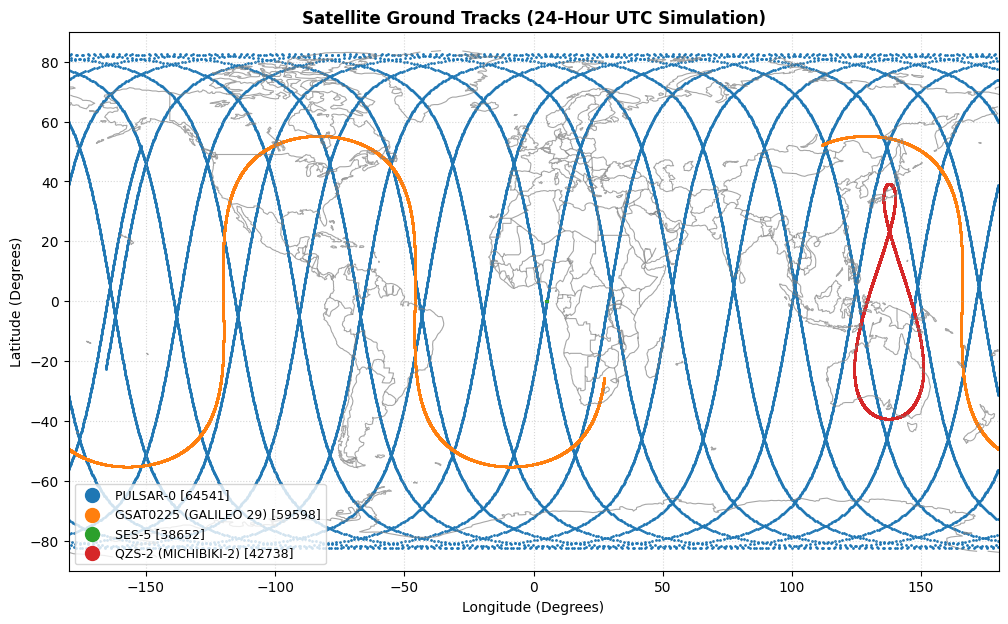

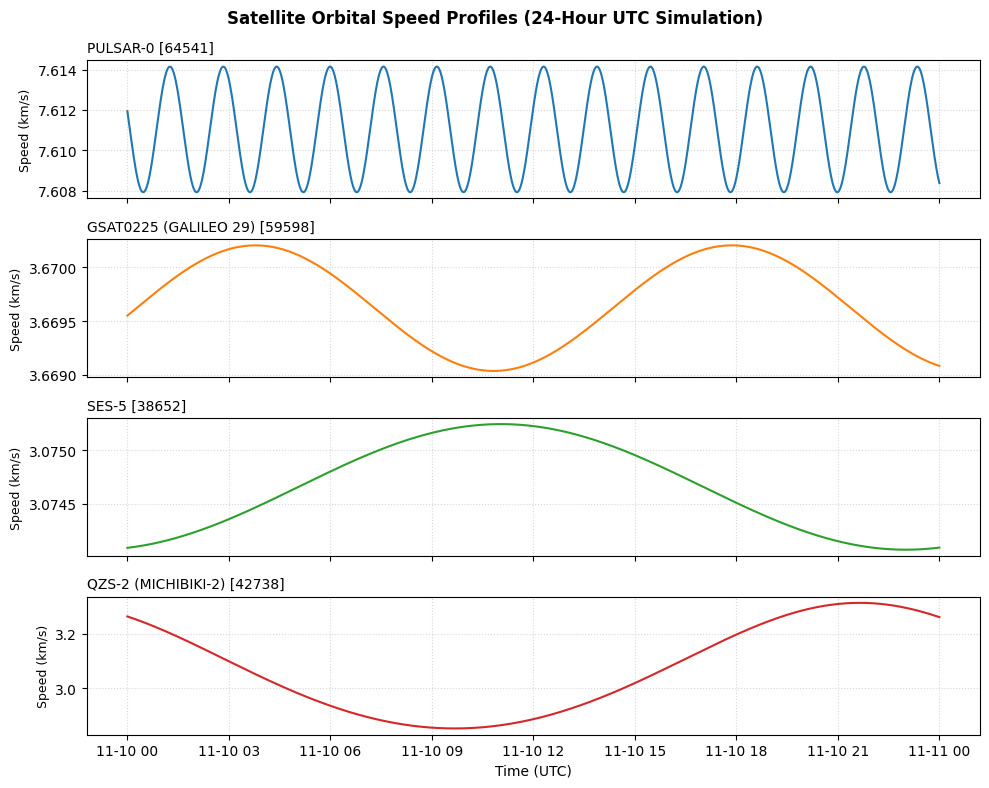

=== Stage 7 Completed Successfully ===
Ground tracks plot saved to: /content/satellite_orbits/output/ground_tracks.png
Velocity timeseries plot saved to: /content/satellite_orbits/output/velocity_timeseries.png


In [9]:
# --- Stage 7: Plots with Matplotlib ---
if 'elements' not in globals() or 'tracks' not in globals():
    raise ValueError("Stage 3/5 outputs not found! Please run preceding cells first.")

def load_coastline(path):
    """
    Loads coastline data from a world_map.txt file.
    Format: Each non-blank line contains 'latitude longitude' (latitude FIRST).
    Blank lines separate distinct coastline segments.
    """
    segments = []
    current_segment = []

    with open(path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_segment:
                    segments.append(current_segment)
                    current_segment = []
            else:
                parts = line.split()
                if len(parts) >= 2:
                    lat = float(parts[0])
                    lon = float(parts[1])
                    current_segment.append((lon, lat))

    if current_segment:
        segments.append(current_segment)

    return segments

# --- Load Coastline Data ---
coastline_segments = load_coastline(IN_DIR / 'world_map.txt')

# --- Define Unified Plot Styles ---
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

# --- Figure 1: 2D Ground Tracks ---
plt.figure(figsize=(12, 7))

# Plot coastline segments
for seg in coastline_segments:
    lons = [p[0] for p in seg]
    lats = [p[1] for p in seg]
    plt.plot(lons, lats, color='gray', linewidth=0.8, alpha=0.7)

# Plot ground track points as discrete scatter dots to prevent wraparound lines
for i, (el, track) in enumerate(zip(elements, tracks)):
    lons = [pt['lon_deg'] for pt in track]
    lats = [pt['lat_deg'] for pt in track]
    plt.scatter(lons, lats, s=1, color=COLORS[i % len(COLORS)], label=el['label'])

plt.title("Satellite Ground Tracks (24-Hour UTC Simulation)", fontsize=12, fontweight='bold')
plt.xlabel("Longitude (Degrees)", fontsize=10)
plt.ylabel("Latitude (Degrees)", fontsize=10)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='lower left', markerscale=10, fontsize=9)

# Save at 200 dpi
ground_track_path = OUT_DIR / 'ground_tracks.png'
plt.savefig(ground_track_path, dpi=200, bbox_inches='tight')
plt.show()

# --- Figure 2: Velocity Timeseries Stacked Plot ---
fig, axs = plt.subplots(len(elements), 1, figsize=(10, 8), sharex=True)

for i, (el, track) in enumerate(zip(elements, tracks)):
    ax = axs[i]
    times_list = [pt['time'] for pt in track]
    speeds = [pt['speed_km_s'] for pt in track]

    ax.plot(times_list, speeds, color=COLORS[i % len(COLORS)], linewidth=1.5)
    ax.set_title(el['label'], fontsize=10, loc='left')
    ax.set_ylabel("Speed (km/s)", fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.ticklabel_format(useOffset=False, axis='y')

axs[-1].set_xlabel("Time (UTC)", fontsize=10)
plt.suptitle("Satellite Orbital Speed Profiles (24-Hour UTC Simulation)", fontsize=12, fontweight='bold')
plt.tight_layout()

# Save timeseries plot
velocity_path = OUT_DIR / 'velocity_timeseries.png'
plt.savefig(velocity_path, dpi=200, bbox_inches='tight')
plt.show()

print("=== Stage 7 Completed Successfully ===")
print(f"Ground tracks plot saved to: {ground_track_path}")
print(f"Velocity timeseries plot saved to: {velocity_path}")

In [12]:
import xml.etree.ElementTree as ET
from matplotlib.colors import to_hex

# --- Helper function to convert Matplotlib color to KML aabbggrr format ---
def matplotlib_to_kml_color(mpl_color_name, alpha_hex="ff"):
    # Get hex color code (e.g., #1f77b4)
    hex_rgb = to_hex(mpl_color_name)
    r = hex_rgb[1:3]
    g = hex_rgb[3:5]
    b = hex_rgb[5:7]
    # KML uses aabbggrr format
    return f"{alpha_hex}{b}{g}{r}"

# --- Register namespaces ---
ET.register_namespace('', 'http://www.opengis.net/kml/2.2')
ET.register_namespace('gx', 'http://www.google.com/kml/ext/2.2')

# ==========================================
# 1. Generate orbit_tracks_ecef.kml
# ==========================================
kml_3d_root = ET.Element('kml', xmlns='http://www.opengis.net/kml/2.2')
doc_3d = ET.SubElement(kml_3d_root, 'Document')
ET.SubElement(doc_3d, 'name').text = 'Multi-Satellite Orbits | Earth-fixed'

for i, (el, track) in enumerate(zip(elements, tracks)):
    color_kml = matplotlib_to_kml_color(COLORS[i % len(COLORS)])
    style_id = f"style_{el['norad_id']}"

    # Style definition
    style = ET.SubElement(doc_3d, 'Style', id=style_id)
    linestyle = ET.SubElement(style, 'LineStyle')
    ET.SubElement(linestyle, 'color').text = color_kml
    ET.SubElement(linestyle, 'width').text = '2'
    iconstyle = ET.SubElement(style, 'IconStyle')
    ET.SubElement(iconstyle, 'color').text = color_kml
    icon = ET.SubElement(iconstyle, 'Icon')
    ET.SubElement(icon, 'href').text = 'http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png'

    # Placemark definition
    placemark = ET.SubElement(doc_3d, 'Placemark')
    ET.SubElement(placemark, 'name').text = el['label']
    ET.SubElement(placemark, 'styleUrl').text = f"#{style_id}"

    linestring = ET.SubElement(placemark, 'LineString')
    ET.SubElement(linestring, 'altitudeMode').text = 'absolute'

    coords_strs = []
    for pt in track:
        # lon,lat,alt (in meters)
        alt_m = pt['alt_km'] * 1000.0
        coords_strs.append(f"{pt['lon_deg']:.6f},{pt['lat_deg']:.6f},{alt_m:.1f}")

    ET.SubElement(linestring, 'coordinates').text = " ".join(coords_strs)

with open(OUT_DIR / 'orbit_tracks_ecef.kml', 'wb') as f:
    ET.ElementTree(kml_3d_root).write(f, encoding='utf-8', xml_declaration=True)

# ==========================================
# 2. Generate orbit_animation.kml
# ==========================================
kml_anim_root = ET.Element('kml',
                           xmlns='http://www.opengis.net/kml/2.2',
                           xmlns_gx='http://www.google.com/kml/ext/2.2')
doc_anim = ET.SubElement(kml_anim_root, 'Document')
ET.SubElement(doc_anim, 'name').text = 'Multi-Satellite Ground Tracks | Animation'

for i, (el, track) in enumerate(zip(elements, tracks)):
    color_kml = matplotlib_to_kml_color(COLORS[i % len(COLORS)])
    style_id = f"style_anim_{el['norad_id']}"

    style = ET.SubElement(doc_anim, 'Style', id=style_id)
    linestyle = ET.SubElement(style, 'LineStyle')
    ET.SubElement(linestyle, 'color').text = color_kml
    ET.SubElement(linestyle, 'width').text = '3'
    iconstyle = ET.SubElement(style, 'IconStyle')
    ET.SubElement(iconstyle, 'color').text = color_kml
    icon = ET.SubElement(iconstyle, 'Icon')
    ET.SubElement(icon, 'href').text = 'http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png'

    placemark = ET.SubElement(doc_anim, 'Placemark')
    ET.SubElement(placemark, 'name').text = el['label']
    ET.SubElement(placemark, 'styleUrl').text = f"#{style_id}"

    multitrack = ET.SubElement(placemark, '{http://www.google.com/kml/ext/2.2}MultiTrack')

    # Segment tracks whenever longitude jumps drastically (wraparound)
    current_track = ET.SubElement(multitrack, '{http://www.google.com/kml/ext/2.2}Track')
    ET.SubElement(current_track, 'altitudeMode').text = 'clampToGround'

    prev_lon = None
    # Keep points every 60 seconds (since simulation is 5-second steps, pick every 12th point)
    for j, pt in enumerate(track):
        if j % 12 != 0:
            continue

        # Check for longitude wrap (> 180 degrees difference)
        if prev_lon is not None and abs(pt['lon_deg'] - prev_lon) > 180.0:
            current_track = ET.SubElement(multitrack, '{http://www.google.com/kml/ext/2.2}Track')
            ET.SubElement(current_track, 'altitudeMode').text = 'clampToGround'

        # Add timestamp <when>
        ts_str = pt['time'].strftime('%Y-%m-%dT%H:%M:%SZ')
        ET.SubElement(current_track, 'when').text = ts_str

        # Add coordinate <gx:coord>
        coord_el = ET.SubElement(current_track, '{http://www.google.com/kml/ext/2.2}coord')
        coord_el.text = f"{pt['lon_deg']:.6f} {pt['lat_deg']:.6f} 0"

        prev_lon = pt['lon_deg']

with open(OUT_DIR / 'orbit_animation.kml', 'wb') as f:
    ET.ElementTree(kml_anim_root).write(f, encoding='utf-8', xml_declaration=True)

# ==========================================
# 3. Generate orbit_report.txt
# ==========================================
report_lines = [
    "Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy",
    "=" * 75,
    source_note,
    f"Simulation Window: {sim_start} to {sim_end} (Step: {STEP_SECONDS} s)",
    "Disclaimer Model Caveat: SGP4 elements propagated in a basic spherical two-body force model (analytical Kepler solver).",
    ""
]

report_lines.append("=== Orbital Keplerian Elements ===")
report_lines.extend(elements_table(elements))
report_lines.append("")
report_lines.append("=== Satellite Orbit Simulation Summaries ===")
report_lines.extend(summary_table(summaries))

with open(OUT_DIR / 'orbit_report.txt', 'w') as f:
    f.write("\n".join(report_lines))

# ==========================================
# 4. Zip all 5 files together
# ==========================================
with zipfile.ZipFile(OUT_DIR / 'satellite_orbit_outputs.zip', 'w') as zipf:
    zipf.write(OUT_DIR / 'ground_tracks.png', arcname='ground_tracks.png')
    zipf.write(OUT_DIR / 'velocity_timeseries.png', arcname='velocity_timeseries.png')
    zipf.write(OUT_DIR / 'orbit_tracks_ecef.kml', arcname='orbit_tracks_ecef.kml')
    zipf.write(OUT_DIR / 'orbit_animation.kml', arcname='orbit_animation.kml')
    zipf.write(OUT_DIR / 'orbit_report.txt', arcname='orbit_report.txt')

print("=== Stage 8: Files generated successfully! ===")
print(f"Outputs bundled in ZIP: {OUT_DIR / 'satellite_orbit_outputs.zip'}")

=== Stage 8: Files generated successfully! ===
Outputs bundled in ZIP: /content/satellite_orbits/output/satellite_orbit_outputs.zip


In [13]:
# --- Download ZIP file ---
from google.colab import files
try:
    files.download(OUT_DIR / 'satellite_orbit_outputs.zip')
    print("Lataus aloitettu onnistuneesti!")
except Exception as e:
    print(f"Virhe latauksessa: {e}. Löydät tiedoston manuaalisesti Colabin vasemman laidan tiedostopaneelista: satellite_orbits/output/satellite_orbit_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Lataus aloitettu onnistuneesti!


### Vaihe 8 Valmis: Tehtävälista ja Google Earth -ohjeet

#### Checklist:
- [x] **2D Ground Tracks & Velocity Plots** tallennettu PNG-muodossa.
- [x] **orbit_tracks_ecef.kml**: Sisältää 3D-radat suhteessa maapalloon.
- [x] **orbit_animation.kml**: Sisältää dynaamisen figure-eight/muun ajastetun animaation maahan kiinnitettynä.
- [x] **orbit_report.txt**: Raportti, jossa on listattuna rataparametrit sekä simulaation yhteenvetotaulukko.
- [x] **satellite_orbit_outputs.zip**: Kaikki edellä mainitut viisi tiedostoa pakattuna yhteen pakettiin.

#### Ohjeet Google Earth Pro -ohjelmassa katseluun:
1. Lataa ja asenna **Google Earth Pro** työpöydällesi (tai käytä selainversiota).
2. Avaa ZIP-paketti ja raahaa tiedostot ohjelmaan:
   - Avaa `orbit_tracks_ecef.kml` tarkastellaksesi satelliittien ratoja 3D-avaruudessa maanpinnan yläpuolella.
   - Avaa `orbit_animation.kml` nähdäksesi satelliittien liikkeen reaaliajassa.
3. Kun avaat animaation, Google Earth Pron vasempaan yläkulmaan ilmestyy **aikajana (Time Slider)**.
4. Napsauta aikajanan **toistopainiketta (Play)** käynnistääksesi simulaation, jolloin näet satelliittien liikkuvan radoillaan 24 tunnin ajan!

In [14]:
import pandas as pd

# Construct list of dictionary records with the requested fields
velocity_diff_data = []
for s in summaries:
    vmin = s['min_speed_km_s']
    vmax = s['max_speed_km_s']
    diff = vmax - vmin
    velocity_diff_data.append({
        'Satellite Name': s['name'],
        'NORAD ID': s['norad_id'],
        'Vmin (km/s)': vmin,
        'Vmax (km/s)': vmax,
        'Difference (km/s)': diff
    })

# Create a DataFrame and sort by the difference descending (greatest first)
df_vel = pd.DataFrame(velocity_diff_data)
df_vel = df_vel.sort_values(by='Difference (km/s)', ascending=False).reset_index(drop=True)

# Display the formatted DataFrame
display(df_vel.style.format({
    'Vmin (km/s)': '{:.4f}',
    'Vmax (km/s)': '{:.4f}',
    'Difference (km/s)': '{:.4f}'
}).hide(axis='index'))

Satellite Name,NORAD ID,Vmin (km/s),Vmax (km/s),Difference (km/s)
QZS-2 (MICHIBIKI-2),42738,2.8533,3.3128,0.4595
PULSAR-0,64541,7.6079,7.6141,0.0062
SES-5,38652,3.0741,3.0752,0.0012
GSAT0225 (GALILEO 29),59598,3.6690,3.6702,0.0012
